# 📩 Spam Message Classifier

### NLP and Machine Learning Project

## 📌 Project Overview
This project classifies SMS messages into two categories:
- **Spam:** Unwanted or promotional messages.
- **Ham:** Legitimate messages.

## 🎯 Objectives
- Clean and preprocess SMS text.
- Convert text into numerical features using TF-IDF.
- Train and compare two machine learning algorithms.
- Evaluate models using classification metrics.
- Test predictions on custom messages.

## 📂 Dataset
SMS Spam Collection Dataset

- Original messages: 5,572
- Messages after cleaning: 5,169
- Ham messages: 4,516
- Spam messages: 653

## 🛠️ Technologies Used
- Python
- Pandas
- Scikit-learn
- TF-IDF Vectorization
- Matplotlib and Seaborn
- Joblib

## 🤖 Models Implemented
1. Multinomial Naive Bayes
2. Logistic Regression

## 📊 Model Evaluation

| Model | Accuracy | Spam Precision | Spam Recall | Spam F1-score |
|---|---:|---:|---:|---:|
| Multinomial Naive Bayes | 96.71% | 100% | 74.05% | 85.09% |
| Logistic Regression | 95.65% | 97.78% | 67.18% | 79.64% |

**Selected model:** Multinomial Naive Bayes, based on the higher Spam F1-score.

## 🧪 Sample Predictions

| Input Message | Prediction |
|---|---|
| Congratulations! You have won a free prize. Claim now! | Spam |
| Hi, are we meeting at college tomorrow? | Legitimate |

## 💾 Saved Model Files
- `models/spam_model.pkl`
- `models/tfidf_vectorizer.pkl`

## ▶️ How to Run
1. Install dependencies using `pip install -r requirements.txt`.
2. Open this notebook in Jupyter.
3. Run the cells from top to bottom.
4. Enter a custom SMS message to test the classifier.

## ✅ Conclusion
The Multinomial Naive Bayes model achieved 96.71% accuracy and a Spam F1-score of 85.09% on the held-out test set. The project demonstrates an end-to-end SMS spam classification workflow using NLP and machine learning.


In [82]:
%pip install pandas scikit-learn matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [83]:

import pandas as pd
import os
print("Current folder:", os.getcwd())

Current folder: C:\Users\lakes


In [84]:
import os
dataset_path = r"C:\Users\lakes\OneDrive\Desktop\CodeNova\Task-2\sms+spam+collection\SMSSpamCollection"
print("Dataset exists:", os.path.exists(dataset_path))

Dataset exists: True


In [85]:

import pandas as pd
df = pd.read_csv(
    dataset_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset loaded successfully!")
print("Total messages:", len(df))
display(df.head())


Dataset loaded successfully!
Total messages: 5572


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [86]:
print(df["label"].value_counts())
print("\nMissing values:")
print(df.isnull().sum())

label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


In [87]:

# Check and clean the dataset
print("Dataset shape:", df.shape)

# Remove any missing messages
df = df.dropna(subset=["label", "message"]).copy()

# Convert labels into lowercase
df["label"] = df["label"].str.lower()

# Remove duplicate messages
df = df.drop_duplicates(subset=["label", "message"])

print("Dataset after cleaning:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())


Dataset shape: (5572, 2)
Dataset after cleaning: (5169, 2)

Class distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [88]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert labels: ham = 0, spam = 1
X = df["message"]
y = df["label"].map({"ham": 0, "spam": 1})

# Split before fitting the vectorizer to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into numerical features
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training messages:", X_train_tfidf.shape[0])
print("Testing messages:", X_test_tfidf.shape[0])
print("Number of text features:", X_train_tfidf.shape[1])


Training messages: 4135
Testing messages: 1034
Number of text features: 7414


In [89]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Create the two models
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

results = {}

# Train and evaluate both models
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)

    results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    ))

# Display comparison table
results_df = pd.DataFrame(results).T
display(results_df.round(4))



Multinomial Naive Bayes
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034


Logistic Regression
              precision    recall  f1-score   support

         Ham       0.95      1.00      0.98       903
        Spam       0.98      0.67      0.80       131

    accuracy                           0.96      1034
   macro avg       0.97      0.83      0.89      1034
weighted avg       0.96      0.96      0.95      1034



,Accuracy,Precision,Recall,F1-Score
Multinomial Naive Bayes,0.9671,1.0000,0.7405,0.8509
Logistic Regression,0.9565,0.9778,0.6718,0.7964


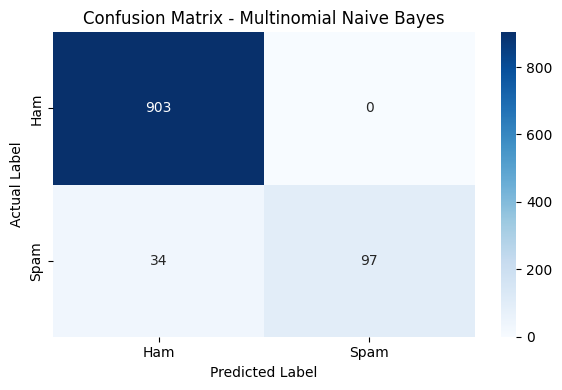

Selected model: Multinomial Naive Bayes


In [90]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Select the model with the highest spam F1-score
best_model_name = max(
    results,
    key=lambda name: results[name]["F1-Score"]
)
best_model = models[best_model_name]

# Predict test messages
y_pred = best_model.predict(X_test_tfidf)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

print("Selected model:", best_model_name)


In [91]:

import joblib
import os

# Create a folder for saved models
os.makedirs("models", exist_ok=True)

# Save the selected model and TF-IDF vectorizer
joblib.dump(best_model, "models/spam_model.pkl")
joblib.dump(vectorizer, "models/tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("Best model:", best_model_name)
print("Files saved inside the models folder.")


Model saved successfully!
Best model: Multinomial Naive Bayes
Files saved inside the models folder.


In [94]:

def predict_spam(message):
    message_tfidf = vectorizer.transform([message])
    prediction = best_model.predict(message_tfidf)[0]

    if prediction == 1:
        print("Result: SPAM MESSAGE")
    else:
        print("Result: LEGITIMATE MESSAGE")

# Try sample messages
predict_spam("Congratulations! You have won a free prize. Claim now!")
predict_spam("Hi, are we meeting at college tomorrow?")

# Enter your own message
user_message = input("Enter a message to check: ")
predict_spam(user_message)


Result: SPAM MESSAGE
Result: LEGITIMATE MESSAGE


Enter a message to check:  Dear Customer, We detected a suspicious login attempt from an unknown device in another country


Result: LEGITIMATE MESSAGE


In [95]:

# Test multiple messages
test_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are you coming to college tomorrow?",
    "URGENT! Your account has been blocked. Click this link now!",
    "Please call me when you are free.",
    "You have won a lottery worth 10 lakh rupees!",
    "Your assignment submission is due tomorrow."
]

for message in test_messages:
    print("\nMessage:", message)
    predict_spam(message)



Message: Congratulations! You have won a free prize. Claim now!
Result: SPAM MESSAGE

Message: Hey, are you coming to college tomorrow?
Result: LEGITIMATE MESSAGE

Message: URGENT! Your account has been blocked. Click this link now!
Result: LEGITIMATE MESSAGE

Message: Please call me when you are free.
Result: LEGITIMATE MESSAGE

Message: You have won a lottery worth 10 lakh rupees!
Result: LEGITIMATE MESSAGE

Message: Your assignment submission is due tomorrow.
Result: LEGITIMATE MESSAGE


Model Accuracy: 0.9671179883945842

Classification Report:

                  precision    recall  f1-score   support

LEGITIMATE (Ham)       0.96      1.00      0.98       903
            SPAM       1.00      0.74      0.85       131

        accuracy                           0.97      1034
       macro avg       0.98      0.87      0.92      1034
    weighted avg       0.97      0.97      0.96      1034



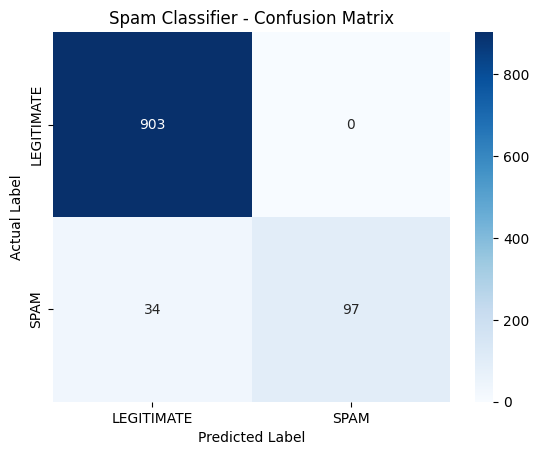

In [96]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Predict on the test dataset
y_pred = best_model.predict(X_test_tfidf)

# Show accuracy and classification report
print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(
    y_test, y_pred, target_names=["LEGITIMATE (Ham)", "SPAM"]
))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["LEGITIMATE", "SPAM"],
    yticklabels=["LEGITIMATE", "SPAM"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Spam Classifier - Confusion Matrix")
plt.show()


In [97]:

import os
import joblib

# Create the models folder
os.makedirs("models", exist_ok=True)

# Save the trained model and vectorizer
joblib.dump(best_model, "models/spam_model.pkl")
joblib.dump(vectorizer, "models/tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("Vectorizer saved successfully!")
print("Model location:", os.path.abspath("models/spam_model.pkl"))
print("Vectorizer location:", os.path.abspath("models/tfidf_vectorizer.pkl"))


Model saved successfully!
Vectorizer saved successfully!
Model location: C:\Users\lakes\models\spam_model.pkl
Vectorizer location: C:\Users\lakes\models\tfidf_vectorizer.pkl


In [98]:

import joblib
import os

# Check whether the files exist
model_path = "models/spam_model.pkl"
vectorizer_path = "models/tfidf_vectorizer.pkl"

if os.path.exists(model_path) and os.path.exists(vectorizer_path):
    loaded_model = joblib.load(model_path)
    loaded_vectorizer = joblib.load(vectorizer_path)

    print("Model loaded successfully!")
    print("Vectorizer loaded successfully!")

    # Test the loaded model
    message = ["Congratulations! You have won a free prize."]
    message_tfidf = loaded_vectorizer.transform(message)
    prediction = loaded_model.predict(message_tfidf)[0]

    if prediction == 1:
        print("Prediction: SPAM MESSAGE")
    else:
        print("Prediction: LEGITIMATE MESSAGE")
else:
    print("Model files not found. Run Step 19 first.")


Model loaded successfully!
Vectorizer loaded successfully!
Prediction: SPAM MESSAGE
